
# Notebook 03 — Model Optimisation and Evaluation

## Objective

In this notebook, I will optimise my Gradient Boosting models, evaluate their performance on unseen test data, analyse feature importance, and save the final prediction pipelines.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

import joblib


In [2]:

# Load the dataset
df = pd.read_csv("../data/energy_efficiency_renamed.csv")

# Separate features and targets
X = df.drop(columns=["Heating_Load", "Cooling_Load"])
y = df[["Heating_Load", "Cooling_Load"]]

# Reproduce the train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Targets:", y_train.shape)
print("Testing Targets:", y_test.shape)


Training Features: (614, 8)
Testing Features: (154, 8)
Training Targets: (614, 2)
Testing Targets: (154, 2)


In [3]:

# Identify feature types
categorical_features = ["Orientation", "Glazing_Area_Distribution"]
numerical_features = [
    col for col in X.columns if col not in categorical_features
]

# Create preprocessing
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

# Create Gradient Boosting pipeline
gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(random_state=42))
])

print("Gradient Boosting pipeline created successfully!")


Gradient Boosting pipeline created successfully!


In [4]:

# Define parameters to test
param_grid = {
    "model__n_estimators": [100, 150],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3]
}

# Tune models for both targets
tuned_models = {}

for target in y_train.columns:
    grid_search = GridSearchCV(
        estimator=gb_pipeline,
        param_grid=param_grid,
        cv=5,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train[target])

    tuned_models[target] = grid_search.best_estimator_

    print(f"\nTarget: {target}")
    print("Best Parameters:", grid_search.best_params_)
    print(f"Best CV MAE: {-grid_search.best_score_:.4f}")



Target: Heating_Load
Best Parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 150}
Best CV MAE: 0.3176

Target: Cooling_Load
Best Parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 150}
Best CV MAE: 1.0417



## Hyperparameter Tuning

I used GridSearchCV to optimise my Gradient Boosting models and identified the best parameters for predicting heating and cooling loads.


In [5]:

# Evaluate tuned models on test data
test_results = {}
test_predictions = {}

for target in y_test.columns:
    model = tuned_models[target]
    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test[target], y_pred)
    rmse = np.sqrt(mean_squared_error(y_test[target], y_pred))
    r2 = r2_score(y_test[target], y_pred)

    test_results[target] = {"MAE": mae, "RMSE": rmse, "R2": r2}
    test_predictions[target] = y_pred

    print(f"\nFinal Test Results for {target}:")
    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R2: {r2:.4f}")



Final Test Results for Heating_Load:
MAE: 0.3464
RMSE: 0.4807
R2: 0.9978

Final Test Results for Cooling_Load:
MAE: 1.0221
RMSE: 1.4552
R2: 0.9771



## Final Model Evaluation

I evaluated my tuned Gradient Boosting models on the unseen test dataset using MAE, RMSE, and R² to assess their predictive performance.

Findings:
- Heating Load achieved MAE = 0.3464, RMSE = 0.4807, and R² = 0.9978.
- Cooling Load achieved MAE = 1.0221, RMSE = 1.4552, and R² = 0.9771.
- My Heating Load model achieved lower prediction errors than my Cooling Load model.
- Both models demonstrated strong predictive performance on the test dataset.



## Actual vs Predicted Energy Loads

Visual comparison of actual and predicted heating and cooling loads to assess model accuracy and prediction errors.


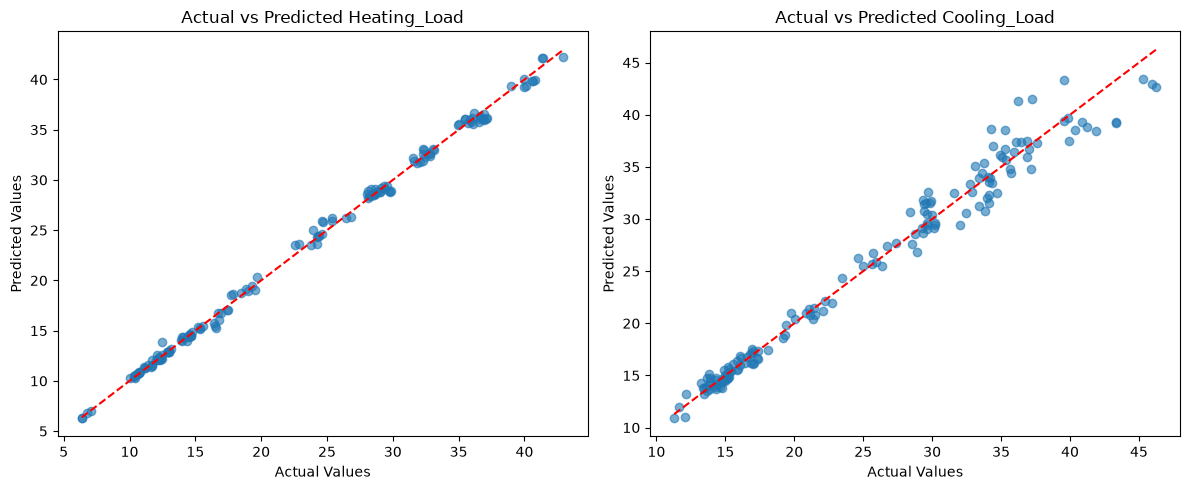

In [6]:

# Visualise actual vs predicted values
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, target in zip(axes, y_test.columns):
    actual = y_test[target]
    predicted = test_predictions[target]

    ax.scatter(actual, predicted, alpha=0.6)

    ax.plot(
        [actual.min(), actual.max()],
        [actual.min(), actual.max()],
        "r--"
    )

    ax.set_title(f"Actual vs Predicted {target}")
    ax.set_xlabel("Actual Values")
    ax.set_ylabel("Predicted Values")

plt.tight_layout()
plt.show()



## Feature Importance Analysis

Permutation importance analysis identifies the architectural features that contribute most to heating and cooling load predictions.


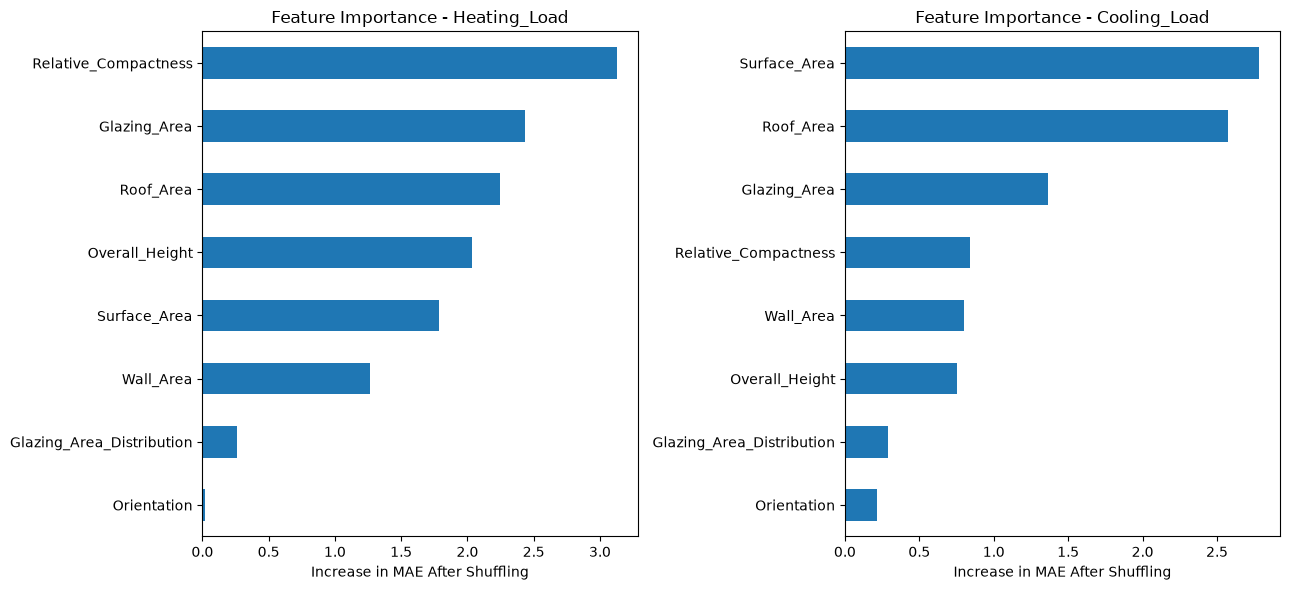

In [7]:

# Calculate permutation importance
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, target in zip(axes, y_test.columns):
    importance = permutation_importance(
        tuned_models[target],
        X_test,
        y_test[target],
        scoring="neg_mean_absolute_error",
        n_repeats=10,
        random_state=42
    )

    feature_importance = pd.Series(
        importance.importances_mean,
        index=X_test.columns
    ).sort_values()

    feature_importance.plot(kind="barh", ax=ax)

    ax.set_title(f"Feature Importance - {target}")
    ax.set_xlabel("Increase in MAE After Shuffling")

plt.tight_layout()
plt.show()



### Feature Importance Findings

- Relative Compactness contributed most to Heating Load predictions.
- Surface Area and Roof Area were the strongest predictors of Cooling Load.
- Glazing Area showed substantial importance for both targets.
- Orientation and Glazing Area Distribution had relatively low importance.
- Correlated features may influence individual importance scores.


In [8]:

# Save final trained models
joblib.dump(tuned_models["Heating_Load"], "../models/heating_model.pkl")
joblib.dump(tuned_models["Cooling_Load"], "../models/cooling_model.pkl")

print("Models saved successfully!")


Models saved successfully!


In [9]:

# Load saved models
heating_model = joblib.load("../models/heating_model.pkl")
cooling_model = joblib.load("../models/cooling_model.pkl")

# Select five test samples
sample = X_test.head()

# Generate predictions
heating_pred = heating_model.predict(sample)
cooling_pred = cooling_model.predict(sample)

# Compare actual and predicted values
results = pd.DataFrame({
    "Actual_Heating": y_test["Heating_Load"].head().values,
    "Predicted_Heating": heating_pred,
    "Actual_Cooling": y_test["Cooling_Load"].head().values,
    "Predicted_Cooling": cooling_pred
})

display(results.round(2))

# Verify saved models reproduce previous predictions
print("Heating Model Verified:",
      np.allclose(heating_pred, test_predictions["Heating_Load"][:5]))

print("Cooling Model Verified:",
      np.allclose(cooling_pred, test_predictions["Cooling_Load"][:5]))


,Actual_Heating,Predicted_Heating,Actual_Cooling,Predicted_Cooling
0,16.47,15.42,16.90,17.14
1,13.17,13.12,16.39,16.20
2,32.82,32.34,32.78,33.39
3,41.32,42.13,46.23,42.64
4,16.69,16.81,19.76,20.95


Heating Model Verified: True
Cooling Model Verified: True



## Conclusion

- I optimised the Gradient Boosting models using GridSearchCV.
- The Heating Load model achieved MAE = 0.3464 and R² = 0.9978.
- The Cooling Load model achieved MAE = 1.0221 and R² = 0.9771.
- Permutation importance revealed the architectural features most influential in each model's predictions.
- Both trained pipelines were successfully saved and reloaded.
- Model verification confirmed consistent predictions after saving.

The models demonstrated strong predictive performance on the UCI test dataset. Further validation would be required for real-world building applications.
